# 1. Question

This is a simulated experiment where treatment effects (+3 pp recovery, +0.8 pp duplicates) are chosen assumptions to demonstrate experimental methods. The central question is whether a redesigned failure experience (contextual messaging, next steps, and status visibility) raises journey recovery without raising duplicate payments. The pre-registered decision rule was locked prior to simulation.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

rep_dir = os.path.abspath(os.path.join(os.getcwd(), 'reports')) if os.path.exists('reports') else os.path.abspath(os.path.join(os.getcwd(), '..', 'reports'))
print('Reports directory:', rep_dir)

Reports directory: D:\Analyst\PaymentIQ\reports


# 2. Design and power

The experiment uses a sticky 50/50 customer-level randomization on 14,250 customers (7,125 per arm), measuring the first recovery-eligible failed journey. At a 32.41 percent recovery baseline, the smallest detectable lift at 80 percent power is 2.22 pp (+3 pp requires 3,906 per arm). The duplicate guardrail (+0.5 pp non-inferiority margin) requires 2,796 per arm and is well powered, supporting margins down to 0.313 pp.

,effect_pp,power,n_per_arm,n_total
0,1,0.8,34658,69316
1,1,0.9,46397,92794
2,2,0.8,8728,17456
3,2,0.9,11684,23368
4,3,0.8,3906,7812
5,3,0.9,5229,10458
6,4,0.8,2211,4422
7,4,0.9,2960,5920
8,5,0.8,1423,2846
9,5,0.9,1905,3810


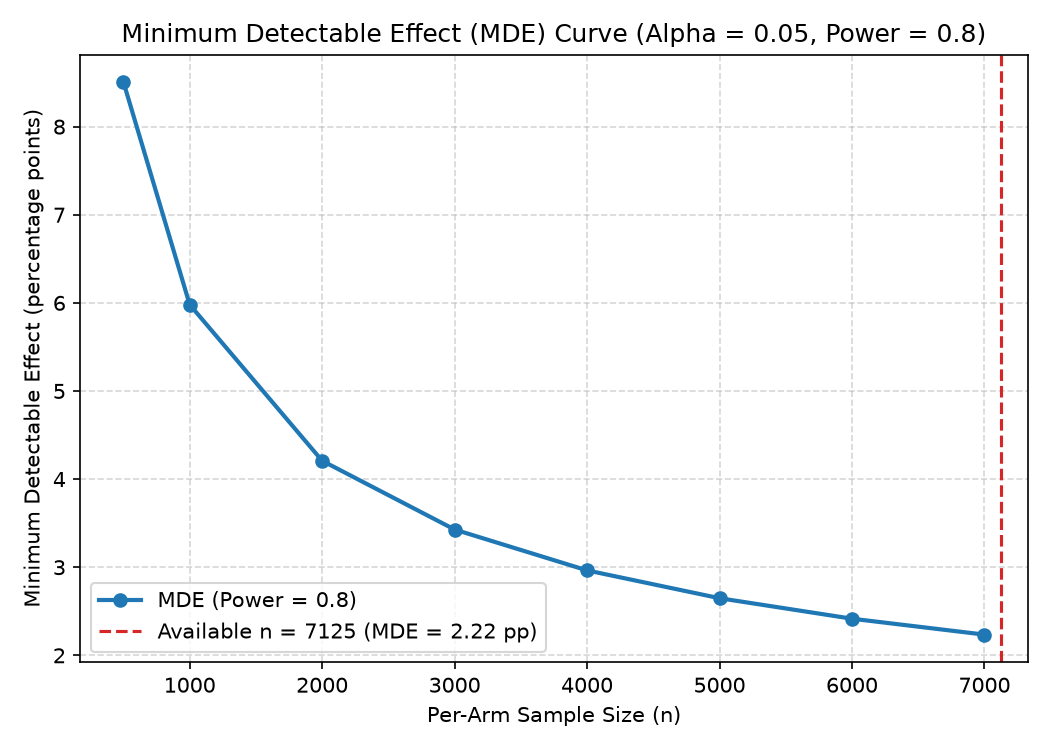

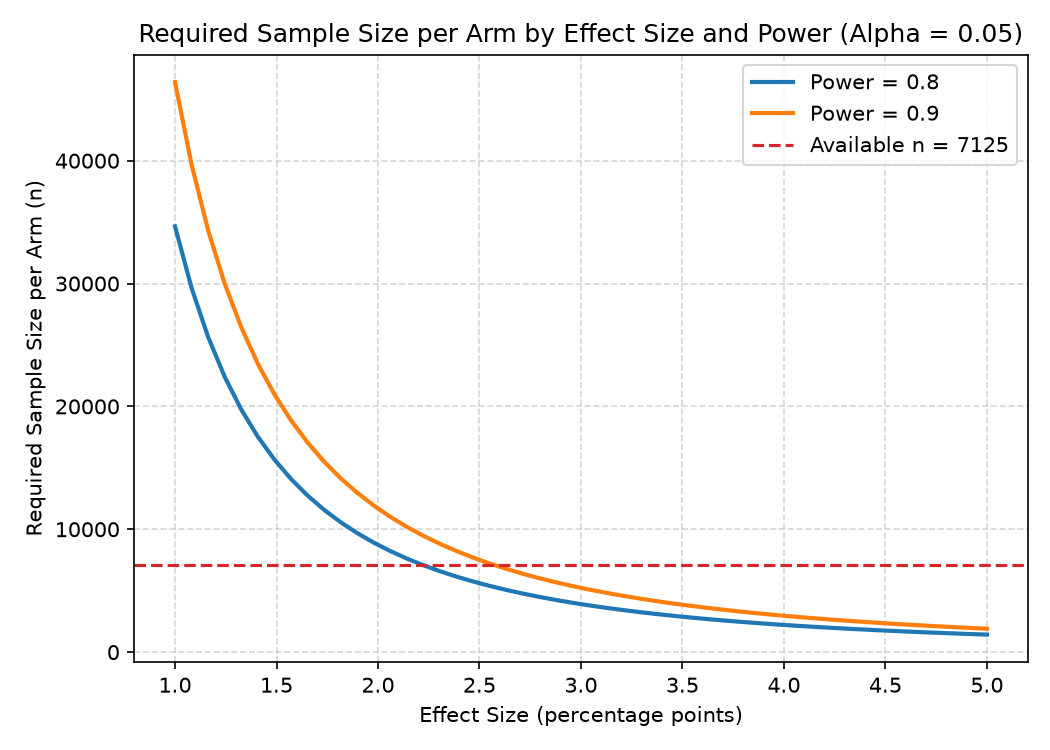

In [2]:
power_df = pd.read_csv(os.path.join(rep_dir, 'phase8_power.csv'))
display(power_df)
display(Image(filename=os.path.join(rep_dir, 'figures', 'p8_mde_curve.png')))
display(Image(filename=os.path.join(rep_dir, 'figures', 'p8_sample_size.png')))

# 3. Three simulated scenarios

Across 1,000 repeats per scenario, Scenario A (+3 pp recovery, 0 dup) achieves a 96.1 percent ship rate with a mean lift of +3.02 pp. Scenario B (null A/A check) yields a 4.6 percent two-sided false-positive rate, confirming pipeline calibration without bias. In Scenario C (+3 pp recovery, +0.8 pp duplicates), the primary metric is significant 96.9 percent of the time, but the guardrail correctly blocks shipping in 99.9 percent of runs.

,scenario,label,ship_rate,ci_lower_gt_0,two_sided_p_lt_05,guardrail_pass,mean_recovery_diff,p2_5_recovery_diff,p97_5_recovery_diff,mean_duplicate_diff,srm_flag_rate
0,A,"Scenario A (+3 pp recovery, 0 dup)",0.961,0.969,0.969,0.991,0.03025,0.01504,0.04549,0.000011,0.000
1,B,Scenario B (Null / A/A),0.023,0.023,0.046,0.988,0.00004,-0.01501,0.01481,0.000017,0.002
2,C,"Scenario C (+3 pp recovery, +0.8 pp dup)",0.001,0.969,0.969,0.001,0.03007,0.01489,0.04475,0.008016,0.001


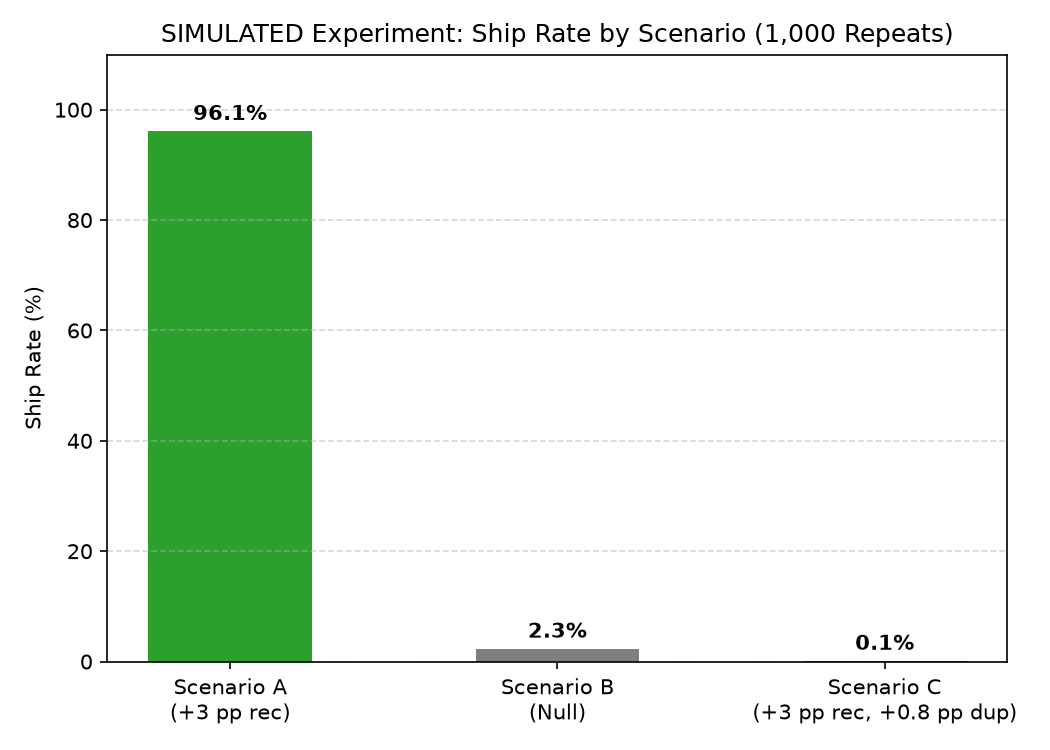

In [3]:
sim_df = pd.read_csv(os.path.join(rep_dir, 'phase8_sim_repeats.csv'))
display(sim_df)
display(Image(filename=os.path.join(rep_dir, 'figures', 'p8_power_study.png')))

# 4. What one run can and cannot tell you

In a single detailed run (seed 88), the true +3 pp lift appeared as +1.93 pp (95 percent CI 0.37 to 3.48), in the lower tail of the repeat distribution. The null run showed -1.34 pp (p = 0.088). Because one experiment is a noisy sample draw, decisions must rely on confidence intervals and pre-registered rules rather than point estimates alone.

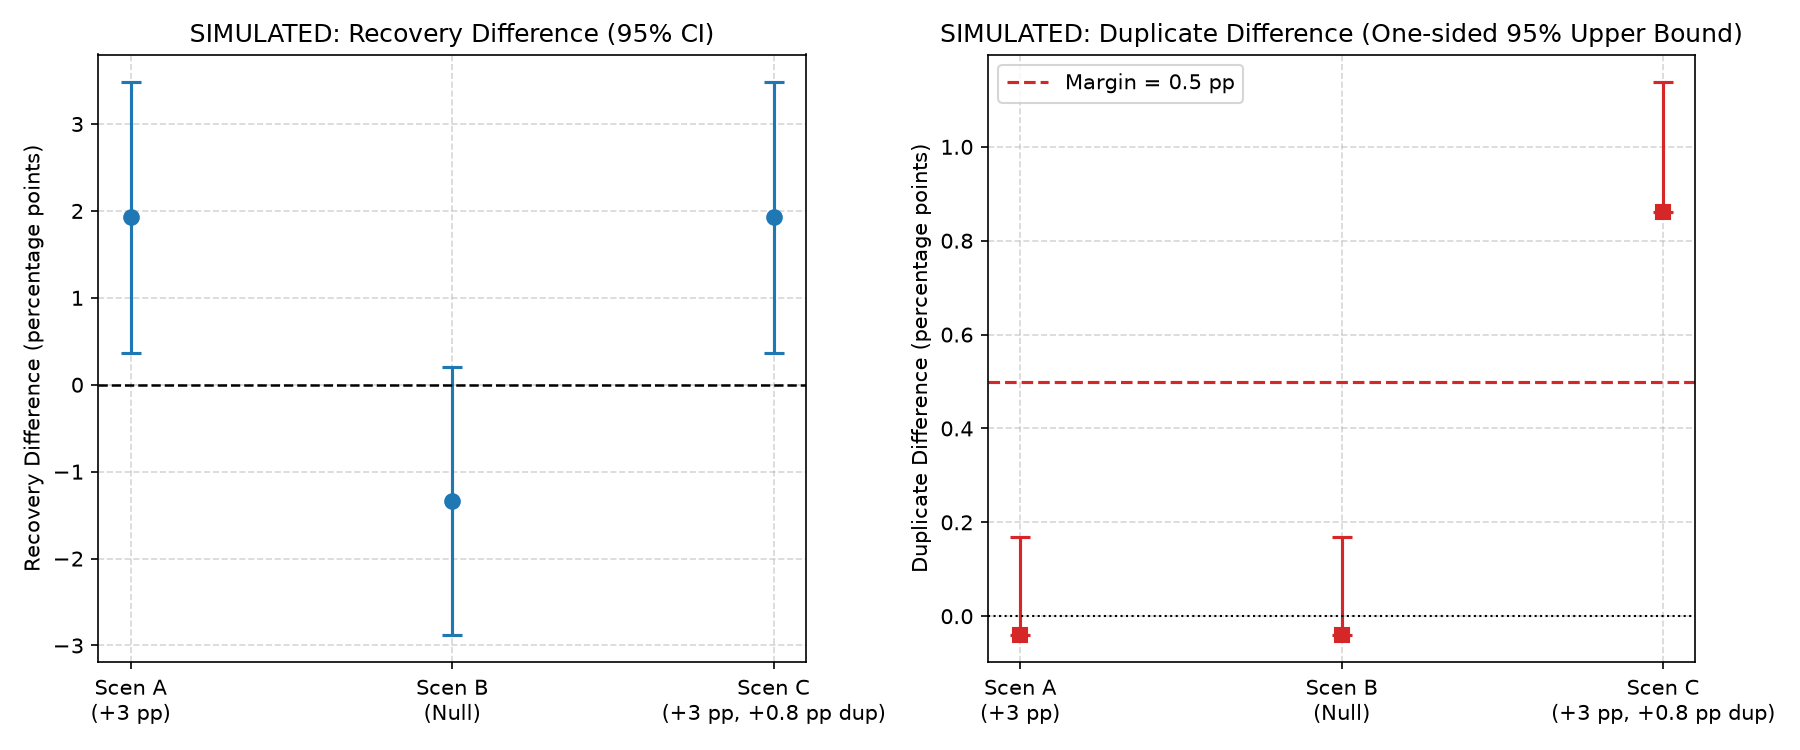

In [4]:
display(Image(filename=os.path.join(rep_dir, 'figures', 'p8_detailed_ci.png')))

# 5. Decision

Under the pre-registered decision rule, Scenario A ships, Scenario B does not ship, and Scenario C does not ship. The inconclusive-on-safety branch did not trigger because the guardrail was sufficiently powered. For a real product redesign, testing would only proceed if expected lift is plausibly 2.5 pp or higher given available sample constraints.

In [5]:
print('Decision rule outcomes: Scenario A -> SHIP, Scenario B -> DO NOT SHIP, Scenario C -> DO NOT SHIP (guardrail override).')

Decision rule outcomes: Scenario A -> SHIP, Scenario B -> DO NOT SHIP, Scenario C -> DO NOT SHIP (guardrail override).


# 6. Limits

All treatment effects are assumed to demonstrate statistical methodology rather than evaluate actual product performance. One observation per customer ignores subsequent journeys, time to completion was not simulated, and the duplicate baseline relies on a detector-based proxy. A production test would require confirmed settlement outcomes and per-failure-type segmentation.

In [6]:
print('Phase 8 experimentation complete: power analysis, MDE, non-inferiority guardrails, and simulation study verified.')

Phase 8 experimentation complete: power analysis, MDE, non-inferiority guardrails, and simulation study verified.
